# Phân tích và dự báo xu hướng giá nhà Phú Hòa – Thủ Dầu Một (phiên bản 2, dữ liệu thật)

**Mã sinh viên:** 2324801030095
**Họ và tên:** Nguyễn Quang Long
**Lớp:** D23KTPM01

**Thay đổi so với phiên bản 1.** Phiên bản 1 tạo **lịch sử giá mô phỏng** 2021–2026 theo giả định, rồi huấn luyện mô hình trên chính dữ liệu đó, nên kết quả chỉ phản ánh giả định. Phiên bản 2 **bỏ hoàn toàn dữ liệu mô phỏng** (bản cũ đã gỡ khỏi project, còn trong lịch sử git). Mọi con số dưới đây tính từ tin rao thật hoặc trích từ báo cáo thị trường đã công bố (có ghi nguồn).

**Dữ liệu thật đang có và chưa có**

| Có | Chưa có (và lý do) |
|---|---|
| Các căn rao bán thật ở Bình Dương cũ (notebook `2324801030095.ipynb`) và các **ảnh chụp có ghi ngày** trong `data/lich_su/` | Lịch sử giá nhiều năm của từng phường: các trang rao vặt chỉ hiển thị tin đang đăng; kho lưu trữ web (Internet Archive) từ chối truy cập tự động từ máy này |
| **Giá gốc lúc đăng** và giá hiện tại của từng tin Chợ Tốt → biết người bán đã tăng hay giảm giá | Giá giao dịch công chứng: không công khai |
| Ngày đăng của từng tin (tháng 9–11/2026) | |
| Số liệu thị trường DKRA Consulting (TP.HCM & vùng phụ cận) đã công bố, có đối chiếu nguyên văn | Số liệu chính thức riêng cho Thủ Dầu Một / Phú Hòa |

**Hệ quả về phương pháp:** với chuỗi thời gian quá ngắn, **không thể huấn luyện và kiểm chứng trung thực** một mô hình học máy dự báo giá 6–12 tháng (không có đủ kỳ quá khứ để kiểm định lùi). Vì vậy notebook:
1. Đo **mặt bằng giá hiện tại** bằng mô hình định giá (Bước 1);
2. Đo **xu hướng ngắn hạn** từ các tín hiệu thật trong dữ liệu (Bước 2–4) và đối chiếu với báo cáo thị trường (Bước 5);
3. Đưa ra **nhận định 6–12 tháng có điều kiện**, ghi rõ cách tính từng con số (Bước 6);
4. Xây sẵn **bộ chỉ số theo ảnh chụp định kỳ** (Bước 7): `thu_thap/cap_nhat_dinh_ky.py` chạy hằng ngày, lưu một ảnh chụp dữ liệu thật mỗi ngày; mỗi tuần là một kỳ của chỉ số. Khi đủ kỳ, mô hình dự báo được huấn luyện và **kiểm định lùi** tự động.

**Phạm vi kiến thức** (toàn bộ notebook này là **phần mở rộng** của đề tài; notebook chính `2324801030095.ipynb` mới là bài làm theo môn học):

| Trong môn học (bài giảng / thực hành) | Ngoài môn học (nâng cao) |
|---|---|
| Khám phá và thống kê mô tả dữ liệu (TH4); ý tưởng đánh giá trên dữ liệu chưa thấy (chia theo thời gian) | Notebook này **không huấn luyện mô hình học máy**: là phân tích tín hiệu thị trường + kịch bản theo kỳ hạn. Làm trơn hàm mũ Holt và kiểm định lùi (backtest) là kỹ thuật chuỗi thời gian, chỉ chạy khi đủ 8 kỳ dữ liệu |

In [1]:
import glob, json, re, warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
nx = lambda s: display(Markdown(s))                                             # in nhận xét có số liệu tính từ kết quả
vn = lambda x, d=1: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")   # 1234.5 -> 1.234,5

import sys
# Thư mục gốc của đề tài: notebook nằm trong notebooks/, mã dùng chung ở src/, dữ liệu ở data/
GOC = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(GOC / "src"))
RAW, PROC, LICH_SU = GOC / "data" / "raw", GOC / "data" / "processed", GOC / "data" / "lich_su"
MODEL_DIR, KET_QUA = GOC / "model", GOC / "ket_qua"
MODEL_DIR.mkdir(exist_ok=True); KET_QUA.mkdir(exist_ok=True); PROC.mkdir(parents=True, exist_ok=True)
from mo_hinh_gia import khong_dau, trich_dac_trung_chu, phan_vi_cho, nhom_khoang

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
rng = np.random.default_rng(42)

df = pd.read_csv(PROC / "nha_da_xu_ly.csv")
goi = joblib.load(MODEL_DIR / "mo_hinh_gia_nha.joblib")
mo_hinh, Q = goi["model"], goi["phan_vi_sai_so"]
raw_ct = pd.read_csv(RAW / "chotot_binh_duong_raw.csv")
TEN_PHUONG = {re.sub(r"^(phuong|xa|thi tran)\s*", "", khong_dau(p)).strip(): re.sub(r"^Phường\s*", "", p)
              for p in raw_ct["phuong"].dropna().unique()}
TEN_PHUONG["phu hoa"] = "Phú Hòa"
print(f"Dữ liệu sạch: {len(df)} căn, mô hình định giá: {goi['ten']} (dữ liệu ngày {goi['ngay_du_lieu']})")

Dữ liệu sạch: 1810 căn, mô hình định giá: LightGBM (dữ liệu ngày 2026-11-24)


## Bước 1: Mặt bằng giá hiện tại – định giá "căn nhà chuẩn" ở từng phường
So đơn giá trung vị thô giữa các phường dễ sai vì mỗi phường rao những loại nhà khác nhau (phường này nhiều nhà mặt tiền lớn, phường kia nhiều nhà hẻm nhỏ). Cách làm chuẩn trong định giá (hedonic): **giữ nguyên một căn nhà mẫu** rồi dùng mô hình định giá nó ở từng vị trí.

**Căn chuẩn:** đất 100 m² (5 × 20 m), 1 trệt 1 lầu (sàn 180 m²), 3 phòng ngủ, 2 WC, hẻm xe hơi rộng 5 m, sổ riêng. Vị trí lấy bằng tọa độ trung vị các tin của phường đó.

,Phường (cũ),Số tin,Giá căn chuẩn (tỷ),Khoảng 80% (tỷ),Đơn giá căn chuẩn (tr/m²),Đơn giá rao trung vị (tr/m²)
1,Phú Thọ,20,3.75,2.66 – 5.31,37.51,41.24
2,Phú Lợi,52,3.70,2.62 – 5.23,36.99,40.66
3,Phú Hòa,218,3.69,2.65 – 5.42,36.92,38.92
4,Hiệp Thành,45,3.68,2.61 – 5.21,36.79,48.97
5,Chánh Nghĩa,32,3.61,2.56 – 5.11,36.14,38.13
6,Phú Mỹ,63,3.49,2.48 – 4.55,34.89,42.11
7,Hoà Phú,33,3.12,2.21 – 4.07,31.19,36.67
8,Chánh Mỹ,94,2.91,2.07 – 3.80,29.10,28.15
9,Hiệp An,24,2.89,2.05 – 3.77,28.87,28.21
10,Tương Bình Hiệp,35,2.66,1.94 – 3.73,26.60,21.23


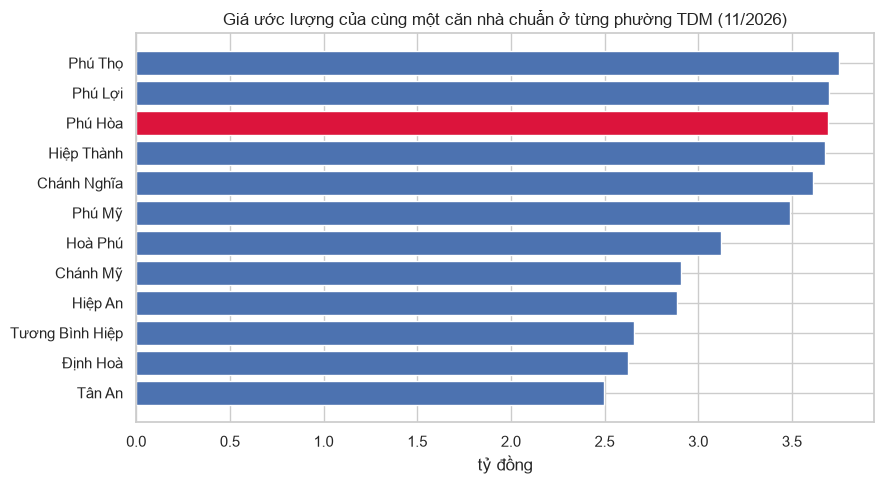

In [2]:
def tao_can(lat, lon, phuong, quan="thu dau mot", duong=None, cap_loi_vao=2, hem_rong=5.0, mat_tien=0,
            dt_dat=100, ngang=5, dai=20, so_tang=2, dt_san=180, phong_ngu=3, so_wc=2, mo_ta="hẻm xe hơi sổ riêng"):
    can = pd.DataFrame([{"dt_dat": dt_dat, "ngang": ngang, "dai": dai, "so_tang": so_tang, "dt_san": dt_san, "phong_ngu": phong_ngu,
                         "so_wc": so_wc, "mat_tien_duong": mat_tien, "cap_loi_vao": cap_loi_vao, "hem_rong": hem_rong,
                         "so_chung": 0.0, "noi_that": np.nan, "quan": quan, "phuong": phuong, "duong": duong,
                         "lat": lat, "lon": lon, "van_ban": khong_dau(mo_ta)}])
    can = pd.concat([can, trich_dac_trung_chu(can["van_ban"])], axis=1)
    can["log_dt"] = np.log(can["dt_dat"]); can["ty_le_san"] = can["dt_san"] / can["dt_dat"]
    can["kc_trung_tam_km"] = np.hypot((lat - 10.9805) * 110.6, (lon - 106.6520) * 109.3)
    return can

def dinh_gia(can):
    p = float(mo_hinh.predict(can)[0])
    q = {k: float(v[0]) for k, v in phan_vi_cho(nhom_khoang(p, goi["khoang_theo_muc"]["nguong"], can["phuong"].iloc[0] == "phu hoa"),
                                                    goi["khoang_theo_muc"]).items()}   # biên độ theo nhóm (Phú Hòa riêng)
    return np.exp(p), np.exp(p + q["q10"]), np.exp(p + q["q90"])

tdm = df[df["quan"] == "thu dau mot"]
rows = []
for ph_, g in tdm.groupby("phuong"):
    if len(g) < 8:
        continue
    gia, lo, hi = dinh_gia(tao_can(g["lat"].median(), g["lon"].median(), ph_))
    rows.append({"Phường (cũ)": TEN_PHUONG.get(ph_, ph_), "Số tin": len(g), "Giá căn chuẩn (tỷ)": gia,
                 "Khoảng 80% (tỷ)": f"{lo:.2f} – {hi:.2f}", "Đơn giá căn chuẩn (tr/m²)": gia * 10,
                 "Đơn giá rao trung vị (tr/m²)": g["don_gia"].median()})
CHUAN = pd.DataFrame(rows).sort_values("Giá căn chuẩn (tỷ)", ascending=False).reset_index(drop=True)
CHUAN.index += 1
display(CHUAN.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
mau = ["crimson" if p == "Phú Hòa" else "#4C72B0" for p in CHUAN["Phường (cũ)"]]
ax.barh(CHUAN["Phường (cũ)"], CHUAN["Giá căn chuẩn (tỷ)"], color=mau); ax.invert_yaxis()
ax.set(title="Giá ước lượng của cùng một căn nhà chuẩn ở từng phường TDM (11/2026)", xlabel="tỷ đồng")
plt.tight_layout(); plt.show()

**Đọc kết quả:** bảng cho biết **vị thế giá** của Phú Hòa so với các phường khác khi so trên cùng một căn nhà. Cột đơn giá rao trung vị (thô) khác cột đơn giá căn chuẩn vì mỗi phường rao loại nhà khác nhau. Đây là lý do cần định giá chuẩn hóa.

Trong Phú Hòa, vị trí và lối vào tạo chênh lệch lớn. Định giá cùng căn chuẩn khi nằm trong hẻm xe hơi và khi nằm ở mặt tiền các trục chính:

In [3]:
ph = df[df["phuong"] == "phu hoa"]
rows = []
lat0, lon0 = ph["lat"].median(), ph["lon"].median()
for ten, kw in [("Hẻm nhỏ 2,5 m", dict(cap_loi_vao=0.5, hem_rong=2.5, mo_ta="hẻm nhỏ sổ riêng")),
                ("Hẻm xe hơi 5 m", dict(cap_loi_vao=2, hem_rong=5)),
                ("Hẻm xe tải 7 m, khu dân cư", dict(cap_loi_vao=4, hem_rong=7, mo_ta="khu dân cư hẻm xe hơi sổ riêng"))]:
    rows.append((ten, *dinh_gia(tao_can(lat0, lon0, "phu hoa", **kw))))
TEN_DUONG = {"nguyen thi minh khai": "Nguyễn Thị Minh Khai", "le hong phong": "Lê Hồng Phong", "nguyen thai binh": "Nguyễn Thái Bình", "phu loi": "Phú Lợi"}
for duong in TEN_DUONG:
    g = df[(df["quan"] == "thu dau mot") & (df["duong"] == duong)]
    if len(g) >= 3:
        rows.append((f"Mặt tiền đường {TEN_DUONG[duong]}", *dinh_gia(tao_can(g["lat"].median(), g["lon"].median(), "phu hoa", duong=duong,
                                                                     cap_loi_vao=5, hem_rong=20, mat_tien=1, mo_ta="mặt tiền kinh doanh sổ riêng"))))
VT = pd.DataFrame(rows, columns=["Vị trí trong Phú Hòa", "Giá (tỷ)", "Thấp 80%", "Cao 80%"]).set_index("Vị trí trong Phú Hòa")
VT["So với hẻm xe hơi (%)"] = (VT["Giá (tỷ)"] / VT.loc["Hẻm xe hơi 5 m", "Giá (tỷ)"] - 1) * 100
VT.round(2)

,Giá (tỷ),Thấp 80%,Cao 80%,So với hẻm xe hơi (%)
Vị trí trong Phú Hòa,,,,
"Hẻm nhỏ 2,5 m",3.62,2.60,5.31,-1.97
Hẻm xe hơi 5 m,3.69,2.65,5.42,0.00
"Hẻm xe tải 7 m, khu dân cư",4.00,2.88,5.87,8.33
Mặt tiền đường Nguyễn Thị Minh Khai,5.25,3.77,7.71,42.22
Mặt tiền đường Lê Hồng Phong,5.53,3.98,8.12,49.83
Mặt tiền đường Nguyễn Thái Bình,5.12,3.68,7.52,38.76
Mặt tiền đường Phú Lợi,5.83,4.19,8.56,57.89


## Bước 2: Tín hiệu 1 – Người bán đang tăng hay giảm giá? (cùng một căn)
Chợ Tốt lưu **giá lúc đăng tin lần đầu** (`gia_goc_luc_dang`) và **giá hiện tại**. Với cùng một căn, mọi khác biệt về diện tích, vị trí, chất lượng đều triệt tiêu, nên đây là thước đo **trực tiếp, sạch nhất** về biến động giá rao trong dữ liệu (cách làm tương tự chỉ số giá lặp lại – *repeat-sales*).

Loại các thay đổi > ±40%: đó là sửa lỗi đơn vị (ví dụ giá ghi thiếu ba số 0), không phải đổi giá.

,Số tin bán,Số tin đã đổi giá,% tin đổi giá,Trong số đổi giá: % GIẢM,KTC 95% của % giảm,Mức đổi trung vị (%),KTC 95% mức đổi,Thay đổi bình quân trên MỌI tin (%)
Toàn Bình Dương cũ,1596,213,13.345865,81.220657,76–86%,-4.054054,-5.0% … -3.6%,-0.653794
Phú Hòa,55,4,7.272727,100.0,100–100%,-7.125027,-18.2% … -3.5%,-0.696149
TDM (phường khác),366,27,7.377049,74.074074,56–89%,-3.333333,-7.3% … -1.6%,-0.324218
Bình Dương cũ (ngoài TDM),1175,182,15.489362,81.868132,76–87%,-4.052343,-5.0% … -3.6%,-0.754249
Toàn TDM,421,31,7.36342,77.419355,61–90%,-4.666667,-7.3% … -2.6%,-0.372887


**Đọc kết quả:** trong 213 tin đã đổi giá (toàn Bình Dương cũ), 81% là giảm giá (KTC 95% 76–86%) → khoảng tin cậy nằm hẳn trên 50%: người bán đang **hạ kỳ vọng** chứ không nâng giá. Mức đổi trung vị -4,1%; tính bình quân trên mọi tin (kể cả tin giữ nguyên giá), mặt bằng giá rao đổi -0,65%.

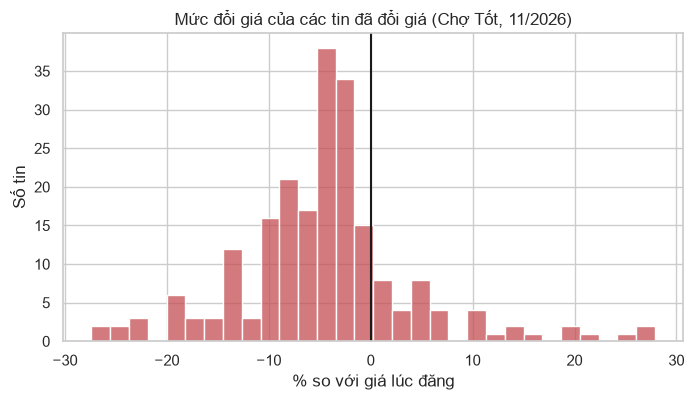

In [4]:
ct = raw_ct[(raw_ct["loai_tin"] == "ban") & raw_ct["gia_goc_luc_dang"].notna() & (raw_ct["gia"] > 0)].copy()
ct["r"] = np.log(ct["gia"] / ct["gia_goc_luc_dang"])
ct["khu_vuc"] = np.where(ct["phuong"] == "Phường Phú Hòa", "Phú Hòa",
                 np.where(ct["quan_huyen"].str.contains("Thủ Dầu Một"), "TDM (phường khác)", "Bình Dương cũ (ngoài TDM)"))
doi = ct[(ct["r"] != 0) & (ct["r"].abs() < np.log(1.4))]

def bootstrap(x, f, n=4000):
    x = np.asarray(x); b = [f(rng.choice(x, len(x))) for _ in range(n)]
    return np.percentile(b, [2.5, 97.5])

def tom_tat(g_all, g_doi):
    if len(g_doi) == 0:
        return pd.Series({"Số tin bán": len(g_all), "Số tin đã đổi giá": 0, "% tin đổi giá": 0.0})
    lo, hi = bootstrap(g_doi["r"], lambda v: np.mean(v < 0)) if len(g_doi) else (np.nan, np.nan)
    mlo, mhi = bootstrap(g_doi["r"], np.median) if len(g_doi) else (np.nan, np.nan)
    return pd.Series({"Số tin bán": len(g_all), "Số tin đã đổi giá": len(g_doi),
                      "% tin đổi giá": len(g_doi) / len(g_all) * 100,
                      "Trong số đổi giá: % GIẢM": np.mean(g_doi["r"] < 0) * 100,
                      "KTC 95% của % giảm": f"{lo*100:.0f}–{hi*100:.0f}%",
                      "Mức đổi trung vị (%)": (np.exp(np.median(g_doi["r"])) - 1) * 100,
                      "KTC 95% mức đổi": f"{(np.exp(mlo)-1)*100:+.1f}% … {(np.exp(mhi)-1)*100:+.1f}%",
                      "Thay đổi bình quân trên MỌI tin (%)": (np.exp(g_all["r"].where(lambda s: s.abs() < np.log(1.4), 0).mean()) - 1) * 100})

BANG_DOI = pd.DataFrame({"Toàn Bình Dương cũ": tom_tat(ct, doi)})
for kv in ["Phú Hòa", "TDM (phường khác)", "Bình Dương cũ (ngoài TDM)"]:
    BANG_DOI[kv] = tom_tat(ct[ct["khu_vuc"] == kv], doi[doi["khu_vuc"] == kv])
tdm_all = ct[ct["khu_vuc"] != "Bình Dương cũ (ngoài TDM)"]
BANG_DOI["Toàn TDM"] = tom_tat(tdm_all, doi[doi["khu_vuc"] != "Bình Dương cũ (ngoài TDM)"])
display(BANG_DOI.T)
r_ = BANG_DOI["Toàn Bình Dương cũ"]
lo_g, hi_g = (map(float, r_["KTC 95% của % giảm"].rstrip("%").split("–")) if r_["Số tin đã đổi giá"] else (np.nan, np.nan))
chieu = ("khoảng tin cậy nằm hẳn trên 50%: người bán đang **hạ kỳ vọng** chứ không nâng giá" if lo_g > 50 else
         "khoảng tin cậy nằm hẳn dưới 50%: người bán đang **nâng giá**" if hi_g < 50 else "khoảng tin cậy chứa 50%: **chưa kết luận được** chiều đổi giá")
nx(f'''**Đọc kết quả:** trong {int(r_["Số tin đã đổi giá"])} tin đã đổi giá (toàn Bình Dương cũ), {vn(r_["Trong số đổi giá: % GIẢM"], 0)}% là giảm giá (KTC 95% {lo_g:.0f}–{hi_g:.0f}%) → {chieu}. Mức đổi trung vị {vn(r_["Mức đổi trung vị (%)"])}%; tính bình quân trên mọi tin (kể cả tin giữ nguyên giá), mặt bằng giá rao đổi {vn(r_["Thay đổi bình quân trên MỌI tin (%)"], 2)}%.''')

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot((np.exp(doi["r"]) - 1) * 100, bins=30, ax=ax, color="#C44E52")
ax.axvline(0, color="k"); ax.set(title="Mức đổi giá của các tin đã đổi giá (Chợ Tốt, 11/2026)", xlabel="% so với giá lúc đăng", ylabel="Số tin")
plt.show()

Các ô "Phú Hòa" có rất ít tin nên chỉ để tham khảo; con số của toàn TDM và toàn vùng đáng tin hơn.

**Cùng phép đo cho căn hộ chung cư** (Chợ Tốt, danh mục "Căn hộ/Chung cư"; định giá căn hộ ở notebook `du_doan_gia_can_ho.ipynb`):

In [5]:
ch = pd.read_csv(RAW / "chotot_can_ho_raw.csv")
ch = ch[(ch["loai_tin"] == "ban") & ch["gia_goc_luc_dang"].notna() & (ch["gia"] > 0)].copy()
ch["r"] = np.log(ch["gia"] / ch["gia_goc_luc_dang"])
doi_ch = ch[(ch["r"] != 0) & (ch["r"].abs() < np.log(1.4))]
la_tdm_ch = ch["quan_huyen"].str.contains("Thủ Dầu Một")
BANG_DOI_CH = pd.DataFrame({"Căn hộ – toàn Bình Dương cũ": tom_tat(ch, doi_ch),
                            "Căn hộ – Thủ Dầu Một": tom_tat(ch[la_tdm_ch], doi_ch[doi_ch["quan_huyen"].str.contains("Thủ Dầu Một")])})
display(BANG_DOI_CH.T)

,Số tin bán,Số tin đã đổi giá,% tin đổi giá,Trong số đổi giá: % GIẢM,KTC 95% của % giảm,Mức đổi trung vị (%),KTC 95% mức đổi,Thay đổi bình quân trên MỌI tin (%)
Căn hộ – toàn Bình Dương cũ,860,154,17.906977,64.935065,57–73%,-2.740247,-3.5% … -1.5%,0.043929
Căn hộ – Thủ Dầu Một,185,26,14.054054,57.692308,38–77%,-3.64084,-5.4% … +5.3%,0.005488


**Đọc kết quả:** so tỷ lệ tin giảm giá của căn hộ với nhà phố ở bảng trên. Nếu cả hai cùng nghiêng về giảm, tín hiệu "người bán hạ kỳ vọng" là chung cho thị trường nhà ở, không riêng một loại hình. Thủ Dầu Một có ít tin căn hộ đổi giá nên chỉ để tham khảo.

## Bước 3: Tín hiệu 2 – Giá rao theo tuần đăng tin
Mỗi căn có **giá rao** và **giá ước lượng** (do mô hình định giá tính ngoài-fold, không học căn đó). Tỷ số log(giá rao / giá ước lượng) đã loại ảnh hưởng của diện tích, vị trí, loại nhà. Nếu các tin đăng gần đây có tỷ số thấp hơn tin đăng trước, mặt bằng giá rao đang đi xuống.

⚠️ **Thiên lệch cần biết:** tin đăng lâu mà vẫn còn hiển thị thường là tin **rao quá cao nên chưa bán được**. Hiện tượng này tự tạo ra một đường "giảm" giả, nên tín hiệu này yếu hơn Bước 2 và chỉ dùng để đối chiếu.

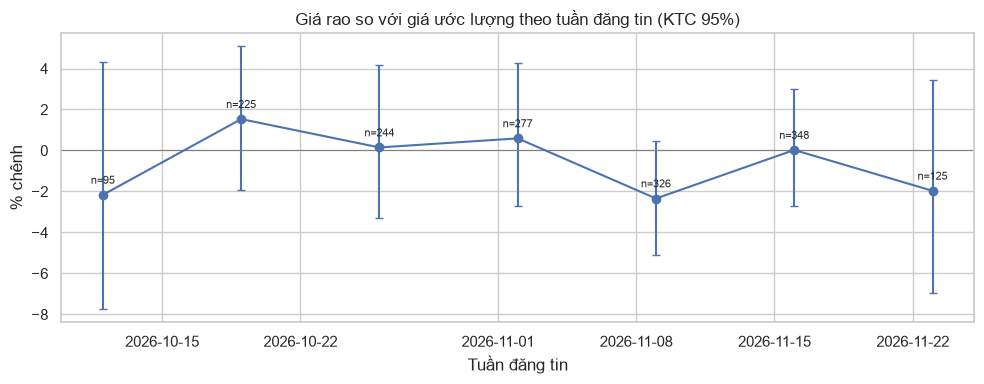

Độ dốc: -3.06 điểm %/tháng (KTC 95%: -6.21 … +0.15); số tin: 1669; giai đoạn: 2026-08-16 → 2026-11-24


In [6]:
d3 = df[df["nguon"].isin(["chotot", "alonhadat"]) & df["ngay_dang"].notna()].copy()
d3["ngay_dang"] = pd.to_datetime(d3["ngay_dang"])
d3["lech"] = np.log(d3["gia_ty"] / d3["gia_uoc_luong_ty"])
d3["tuan"] = d3["ngay_dang"].dt.to_period("W").dt.start_time
tuan = d3.groupby("tuan")["lech"].agg(["size", "mean"]).query("size >= 15")
ci = np.array([bootstrap(d3.loc[d3["tuan"] == t, "lech"], np.mean, 1000) for t in tuan.index])
ngay_so = (d3["ngay_dang"] - d3["ngay_dang"].min()).dt.days.to_numpy()
def doc(idx):
    return np.polyfit(ngay_so[idx], d3["lech"].to_numpy()[idx], 1)[0] * 30 * 100
slope = doc(np.arange(len(d3)))
slo, shi = np.percentile([doc(rng.integers(0, len(d3), len(d3))) for _ in range(2000)], [2.5, 97.5])

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(tuan.index, (np.exp(tuan["mean"]) - 1) * 100, yerr=[(np.exp(tuan["mean"]) - np.exp(ci[:, 0])) * 100, (np.exp(ci[:, 1]) - np.exp(tuan["mean"])) * 100],
            fmt="o-", capsize=3)
for t, n in tuan["size"].items():
    ax.annotate(f"n={n}", (t, (np.exp(tuan.loc[t, "mean"]) - 1) * 100), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.axhline(0, color="gray", lw=0.8)
ax.set(title="Giá rao so với giá ước lượng theo tuần đăng tin (KTC 95%)", ylabel="% chênh", xlabel="Tuần đăng tin")
plt.tight_layout(); plt.show()
print(f"Độ dốc: {slope:+.2f} điểm %/tháng (KTC 95%: {slo:+.2f} … {shi:+.2f}); số tin: {len(d3)}; "
      f"giai đoạn: {d3['ngay_dang'].min().date()} → {d3['ngay_dang'].max().date()}")

**Đọc kết quả:** đọc độ dốc cùng khoảng tin cậy. Nếu khoảng tin cậy chứa 0 thì giai đoạn dữ liệu hiện có (in ở dòng trên) **chưa đủ** để khẳng định giá rao tăng hay giảm theo thời gian. Nếu âm rõ, cần nhớ một phần đến từ thiên lệch "tin cũ là tin rao cao" ở trên.

## Bước 4: Tín hiệu 3 – Áp lực bán
- Tỷ lệ tin có từ khóa **"bán gấp / ngộp / cắt lỗ / giảm giá / kẹt tiền"**;
- Tỷ lệ tin được mô hình chẩn đoán **"rẻ hơn thị trường"** và **"cao hơn thị trường"** (từ notebook chính).

In [7]:
df["khu_vuc"] = np.where(df["phuong"] == "phu hoa", "Phú Hòa", np.where(df["quan"] == "thu dau mot", "TDM (phường khác)", "Ngoài TDM"))
AP_LUC = df.groupby("khu_vuc").agg(so_can=("y", "size"), ban_gap_pt=("t_ban_gap", "mean"),
                                    re_hon_pt=("chan_doan", lambda s: (s == "Rẻ hơn thị trường").mean()),
                                    cao_hon_pt=("chan_doan", lambda s: (s == "Cao hơn thị trường").mean()),
                                    lech_tv_pt=("chenh_lech_pt", "median"))
AP_LUC[["ban_gap_pt", "re_hon_pt", "cao_hon_pt"]] *= 100
AP_LUC.columns = ["Số căn", "% tin 'bán gấp/giảm giá'", "% rẻ hơn thị trường", "% cao hơn thị trường", "Giá rao lệch trung vị so với ước lượng (%)"]
display(AP_LUC.round(1))
bg, re_, cao_ = AP_LUC["% tin 'bán gấp/giảm giá'"], AP_LUC["% rẻ hơn thị trường"].mean(), AP_LUC["% cao hơn thị trường"].mean()
nx(f'''**Đọc kết quả:** {vn(bg.min(), 0)}–{vn(bg.max(), 0)}% số tin (tùy khu vực) có lời lẽ "bán gấp / giảm giá" (Phú Hòa {vn(bg.get("Phú Hòa", np.nan), 0)}%). Tỷ lệ này càng cao thì thị trường càng **thuận lợi cho người mua**. Trung bình các khu vực, {vn(re_, 0)}% căn "rẻ hơn" và {vn(cao_, 0)}% căn "cao hơn thị trường" → {"xấp xỉ nhau: mặt bằng giá rao **chưa lệch hẳn về một phía** so với giá trị ước lượng" if abs(re_ - cao_) < 5 else ("nhiều căn rao **thấp** hơn ước lượng" if re_ > cao_ else "nhiều căn rao **cao** hơn ước lượng")}.''')

,Số căn,% tin 'bán gấp/giảm giá',% rẻ hơn thị trường,% cao hơn thị trường,Giá rao lệch trung vị so với ước lượng (%)
khu_vuc,,,,,
Ngoài TDM,1130,21.9,11.5,7.3,0.1
Phú Hòa,218,10.6,10.6,9.2,-0.5
TDM (phường khác),462,17.1,9.7,8.9,2.4


**Đọc kết quả:** 11–22% số tin (tùy khu vực) có lời lẽ "bán gấp / giảm giá" (Phú Hòa 11%). Tỷ lệ này càng cao thì thị trường càng **thuận lợi cho người mua**. Trung bình các khu vực, 11% căn "rẻ hơn" và 8% căn "cao hơn thị trường" → xấp xỉ nhau: mặt bằng giá rao **chưa lệch hẳn về một phía** so với giá trị ước lượng.

## Bước 5: Bối cảnh thị trường đã công bố
Các số liệu dưới đây đã được đối chiếu với **nguyên văn** bài báo. Chúng là số liệu của **TP.HCM và vùng phụ cận** (gồm Bình Dương cũ), không riêng Thủ Dầu Một, và các mốc so sánh khác nhau (so cùng kỳ / quý trước / tháng trước). Vì vậy **không ghép thành một chuỗi số**, chỉ dùng để xác định chiều của thị trường.

In [8]:
BOI_CANH = pd.DataFrame([
    ["2025 (tổng kết năm)", "Nhà phố, biệt thự – thứ cấp", "+12 – 19% so với đầu năm", "Tiếp Thị Gia Đình, 12/01/2026 (số liệu năm 2025 không ghi rõ đơn vị; phần dự báo ghi DKRA)",
     "https://tiepthigiadinh.vn/du-bao-thi-truong-bat-dong-san-nam-2026-d30043.html"],
    ["2 tháng đầu 2026", "Nhà phố, biệt thự – thứ cấp", "Đi ngang so với Q4/2025; +13 – 17% so với cùng kỳ 2025", "DKRA Consulting, qua Nhịp sống kinh doanh 17/03/2026",
     "https://nhipsongkinhdoanh.vn/bat-dong-san-phia-nam-2-thang-dau-nam-2026--bat-ngo-mot-phan-khuc-giao-dich-tang-31-lan-26667.htm"],
    ["Quý II/2026", "Nhà phố, biệt thự – thứ cấp", "+2% so với quý trước, cục bộ ở dự án hoàn thiện pháp lý", "DKRA Consulting, qua Việt Báo 11/07/2026",
     "https://vietbao.vn/can-ho-dat-nen-nha-pho-biet-thu-tp-ho-chi-minh-co-chuyen-dong-moi-598552.html"],
    ["Tháng 10/2026", "Nhà phố, biệt thự – thứ cấp", "−8% so với tháng trước; tiêu thụ chỉ ~5% nguồn cung; sơ cấp đi ngang", "DKRA Consulting, qua CafeF 13/11/2026",
     "https://cafef.vn/tphcm-cu-100-can-biet-thu-nha-pho-duoc-ban-ra-thi-co-toi-95-can-khong-ban-duoc-188261113135928595.chn"],
], columns=["Thời điểm", "Phân khúc", "Biến động giá", "Nguồn", "Link"])
BOI_CANH

,Thời điểm,Phân khúc,Biến động giá,Nguồn,Link
0,2025 (tổng kết năm),"Nhà phố, biệt thự – thứ cấp",+12 – 19% so với đầu năm,"Tiếp Thị Gia Đình, 12/01/2026 (số liệu năm 202...",https://tiepthigiadinh.vn/du-bao-thi-truong-ba...
1,2 tháng đầu 2026,"Nhà phố, biệt thự – thứ cấp",Đi ngang so với Q4/2025; +13 – 17% so với cùng...,"DKRA Consulting, qua Nhịp sống kinh doanh 17/0...",https://nhipsongkinhdoanh.vn/bat-dong-san-phia...
2,Quý II/2026,"Nhà phố, biệt thự – thứ cấp","+2% so với quý trước, cục bộ ở dự án hoàn thiệ...","DKRA Consulting, qua Việt Báo 11/07/2026",https://vietbao.vn/can-ho-dat-nen-nha-pho-biet...
3,Tháng 10/2026,"Nhà phố, biệt thự – thứ cấp",−8% so với tháng trước; tiêu thụ chỉ ~5% nguồn...,"DKRA Consulting, qua CafeF 13/11/2026",https://cafef.vn/tphcm-cu-100-can-biet-thu-nha...


**Đọc kết quả:** giá nhà phố thứ cấp khu vực tăng mạnh trong 2025 và đầu 2026, chậm lại ở quý II/2026, rồi **đảo chiều giảm** ở tháng 10/2026 khi thanh khoản rất thấp. Diễn biến này **cùng chiều** với tín hiệu từ dữ liệu của đề tài (Bước 2, 4): người bán ở Thủ Dầu Một đang giảm giá nhiều hơn tăng giá.

## Bước 6: Kịch bản tham khảo cho các kỳ hạn 1–24 tháng (chưa phải dự báo đã kiểm chứng)
Tổng hợp các tín hiệu (chỉ dùng số đo được ở trên). Đây là **kịch bản có điều kiện**, suy ra từ tín hiệu hiện tại; nó **chưa được kiểm định lùi** vì mới có vài kỳ dữ liệu (Bước 7), nên không được đọc như một dự báo có độ chính xác đã biết.

In [9]:
tdm_row = BANG_DOI["Toàn TDM"]
ph_row = BANG_DOI["Phú Hòa"]
TIN_HIEU = pd.DataFrame([
    ["Đổi giá cùng một căn (TDM)", f"{tdm_row['Trong số đổi giá: % GIẢM']:.0f}% số lần đổi giá là GIẢM; mức đổi trung vị {tdm_row['Mức đổi trung vị (%)']:+.1f}%",
     "Giảm" if tdm_row["Trong số đổi giá: % GIẢM"] > 50 else "Tăng", "Cao – đo trực tiếp trên cùng căn"],
    ["Đổi giá cùng một căn (toàn vùng)", f"{BANG_DOI['Toàn Bình Dương cũ']['Trong số đổi giá: % GIẢM']:.0f}% là GIẢM; trung vị {BANG_DOI['Toàn Bình Dương cũ']['Mức đổi trung vị (%)']:+.1f}%",
     "Giảm" if BANG_DOI["Toàn Bình Dương cũ"]["Trong số đổi giá: % GIẢM"] > 50 else "Tăng", "Cao"],
    ["Đổi giá cùng một căn hộ chung cư (toàn vùng)", f"{BANG_DOI_CH.loc['Trong số đổi giá: % GIẢM', 'Căn hộ – toàn Bình Dương cũ']:.0f}% là GIẢM; trung vị {BANG_DOI_CH.loc['Mức đổi trung vị (%)', 'Căn hộ – toàn Bình Dương cũ']:+.1f}%",
     "Giảm" if BANG_DOI_CH.loc['Trong số đổi giá: % GIẢM', 'Căn hộ – toàn Bình Dương cũ'] > 50 else "Tăng", "Cao"],
    ["Giá rao theo tuần đăng", f"{slope:+.2f} điểm %/tháng (KTC 95% {slo:+.2f} … {shi:+.2f})",
     "Giảm" if shi < 0 else ("Tăng" if slo > 0 else "Chưa rõ"), "Thấp – có thiên lệch tin tồn"],
    ["Tin 'bán gấp/giảm giá' (TDM)", f"{df[df['quan'] == 'thu dau mot']['t_ban_gap'].mean() * 100:.0f}% số tin", "Giảm", "Trung bình"],
    ["DKRA – nhà phố thứ cấp T10/2026", "−8% so với tháng trước, tiêu thụ ~5% nguồn cung", "Giảm", "Trung bình – số liệu vùng"],
    ["DKRA – nhà phố thứ cấp 12 tháng trước đó", "+13–17% so với cùng kỳ (đầu 2026)", "Tăng (đã qua)", "Trung bình – số liệu vùng"],
], columns=["Tín hiệu", "Giá trị đo được", "Chiều", "Độ tin cậy"])
display(TIN_HIEU)

# Biên của kịch bản: lấy trực tiếp từ các con số đo được, không tự đặt
giam_6t = min(tdm_row["Mức đổi trung vị (%)"], BANG_DOI["Toàn Bình Dương cũ"]["Mức đổi trung vị (%)"])   # mức người bán đang giảm
tang_6t = 2.0                                                    # DKRA Q2/2026: +2%/quý – mức tăng gần nhất trước khi đảo chiều
# Kỳ hạn bất kỳ: chia đều biên 6 tháng thành biên mỗi tháng rồi nhân với số tháng (6 và 12 tháng giữ đúng như trước).
# Cách này GIẢ ĐỊNH tín hiệu hiện tại kéo dài; càng xa càng kém chắc chắn, nên mỗi kỳ hạn có nhãn độ tin cậy.
THANG_LO, THANG_HI = giam_6t / 6, tang_6t / 6
def muc_tin_cay(h):
    return ("Ngắn hạn – sát tín hiệu hiện tại" if h <= 3 else "Kịch bản tham khảo" if h <= 6 else "Bất định cao" if h <= 12
            else "Chỉ minh họa – ngoài phạm vi dữ liệu")
def xu_huong(lo, hi):
    m = (lo + hi) / 2
    return "Đi ngang" if abs(m) <= 0.5 else ("Giảm nhẹ" if m > -3 else "Giảm") if m < 0 else ("Tăng nhẹ" if m < 3 else "Tăng")
thang_toi = lambda h: (pd.Timestamp(goi["ngay_du_lieu"]) + pd.DateOffset(months=h)).strftime("%m/%Y")
KY_HAN = [1, 3, 6, 12, 18, 24]
DU_BAO = pd.DataFrame([[f"{h} tháng (đến {thang_toi(h)})", xu_huong(THANG_LO * h, THANG_HI * h), f"{THANG_LO * h:+.1f}% … {THANG_HI * h:+.1f}%", muc_tin_cay(h)]
                       for h in KY_HAN], columns=["Kỳ hạn", "Xu hướng giá rao nhà phố Phú Hòa / TDM", "Biên độ ước tính", "Độ tin cậy"])
DU_BAO["thang"] = KY_HAN
display(DU_BAO.drop(columns="thang"))
print(f"Biên mỗi tháng: {THANG_LO:+.2f}% … {THANG_HI:+.2f}%. Biên dưới 6 tháng = mức giảm trung vị người bán đang áp dụng ({giam_6t:+.1f}%); "
      f"biên trên 6 tháng = mức tăng quý gần nhất trước khi thị trường đảo chiều (DKRA Q2/2026, {tang_6t:+.1f}%). "
      "Kỳ hạn khác = biên mỗi tháng × số tháng. Trang demo cho chọn kỳ hạn 1–12, 18, 24 tháng theo đúng công thức này.")
ktc_t = tdm_row.get("KTC 95% của % giảm")
lo_t, hi_t = map(float, ktc_t.rstrip("%").split("–")) if isinstance(ktc_t, str) else (np.nan, np.nan)
giam_ro, tang_ro = lo_t > 50, hi_t < 50
xh = dict(zip(DU_BAO["thang"], DU_BAO["Xu hướng giá rao nhà phố Phú Hòa / TDM"]))
hien_tai = (f"mặt bằng giá rao ở Thủ Dầu Một đang **điều chỉnh giảm**: {tdm_row['Trong số đổi giá: % GIẢM']:.0f}% số lần người bán đổi giá là **hạ giá** "
            f"(KTC 95% {lo_t:.0f}–{hi_t:.0f}%, nằm hẳn trên 50%)" if giam_ro else
            f"người bán đang **nâng giá** ({tdm_row['Trong số đổi giá: % GIẢM']:.0f}% số lần đổi giá là hạ giá, KTC nằm hẳn dưới 50%)" if tang_ro else
            "**chưa rõ chiều**: tỷ lệ hạ giá trong các lần đổi giá có khoảng tin cậy chứa 50%")
nx(f'''**Kết luận xu hướng (cần trình bày đúng mức độ chắc chắn):**
- **Hiện tại ({pd.Timestamp(goi["ngay_du_lieu"]).strftime("%m/%Y")}):** {hien_tai}; DKRA tháng 10/2026 ghi nhận giá nhà phố thứ cấp giảm (bảng tín hiệu).
- **1–3 tháng tới:** biên độ hẹp (xem bảng); xu hướng theo kịch bản: **{xh[1].lower()}** (1 tháng), **{xh[3].lower()}** (3 tháng).
- **6 tháng tới (kịch bản tham khảo, chưa kiểm định):** **{xh[6].lower()}**.{" Khả năng tăng mạnh trở lại trong ngắn hạn thấp vì người bán đang hạ giá." if giam_ro else ""}''')

,Tín hiệu,Giá trị đo được,Chiều,Độ tin cậy
0,Đổi giá cùng một căn (TDM),77% số lần đổi giá là GIẢM; mức đổi trung vị -...,Giảm,Cao – đo trực tiếp trên cùng căn
1,Đổi giá cùng một căn (toàn vùng),81% là GIẢM; trung vị -4.1%,Giảm,Cao
2,Đổi giá cùng một căn hộ chung cư (toàn vùng),65% là GIẢM; trung vị -2.7%,Giảm,Cao
3,Giá rao theo tuần đăng,-3.06 điểm %/tháng (KTC 95% -6.21 … +0.15),Chưa rõ,Thấp – có thiên lệch tin tồn
4,Tin 'bán gấp/giảm giá' (TDM),15% số tin,Giảm,Trung bình
5,DKRA – nhà phố thứ cấp T10/2026,"−8% so với tháng trước, tiêu thụ ~5% nguồn cung",Giảm,Trung bình – số liệu vùng
6,DKRA – nhà phố thứ cấp 12 tháng trước đó,+13–17% so với cùng kỳ (đầu 2026),Tăng (đã qua),Trung bình – số liệu vùng


,Kỳ hạn,Xu hướng giá rao nhà phố Phú Hòa / TDM,Biên độ ước tính,Độ tin cậy
0,1 tháng (đến 12/2026),Đi ngang,-0.8% … +0.3%,Ngắn hạn – sát tín hiệu hiện tại
1,3 tháng (đến 02/2027),Giảm nhẹ,-2.3% … +1.0%,Ngắn hạn – sát tín hiệu hiện tại
2,6 tháng (đến 05/2027),Giảm nhẹ,-4.7% … +2.0%,Kịch bản tham khảo
3,12 tháng (đến 11/2027),Giảm nhẹ,-9.3% … +4.0%,Bất định cao
4,18 tháng (đến 05/2028),Giảm,-14.0% … +6.0%,Chỉ minh họa – ngoài phạm vi dữ liệu
5,24 tháng (đến 11/2028),Giảm,-18.7% … +8.0%,Chỉ minh họa – ngoài phạm vi dữ liệu


Biên mỗi tháng: -0.78% … +0.33%. Biên dưới 6 tháng = mức giảm trung vị người bán đang áp dụng (-4.7%); biên trên 6 tháng = mức tăng quý gần nhất trước khi thị trường đảo chiều (DKRA Q2/2026, +2.0%). Kỳ hạn khác = biên mỗi tháng × số tháng. Trang demo cho chọn kỳ hạn 1–12, 18, 24 tháng theo đúng công thức này.


**Kết luận xu hướng (cần trình bày đúng mức độ chắc chắn):**
- **Hiện tại (11/2026):** mặt bằng giá rao ở Thủ Dầu Một đang **điều chỉnh giảm**: 77% số lần người bán đổi giá là **hạ giá** (KTC 95% 61–90%, nằm hẳn trên 50%); DKRA tháng 10/2026 ghi nhận giá nhà phố thứ cấp giảm (bảng tín hiệu).
- **1–3 tháng tới:** biên độ hẹp (xem bảng); xu hướng theo kịch bản: **đi ngang** (1 tháng), **giảm nhẹ** (3 tháng).
- **6 tháng tới (kịch bản tham khảo, chưa kiểm định):** **giảm nhẹ**. Khả năng tăng mạnh trở lại trong ngắn hạn thấp vì người bán đang hạ giá.

- **12 tháng tới:** biên độ rộng; **18–24 tháng** chỉ là minh họa khi kéo dài tín hiệu hiện tại, không nên dùng để ra quyết định; chiều đi phụ thuộc lãi suất, tín dụng và hạ tầng (sáp nhập vào TP.HCM, kết nối vùng). **Không đủ dữ liệu lịch sử thật để đưa một con số chính xác** mà không phải tự đặt giả định. Đây là giới hạn trung thực của đề tài.
- Với người mua ở Phú Hòa: dùng khoảng giá 80% của mô hình định giá (notebook chính) làm mốc trả giá; khi người bán đang hạ giá (dòng "Hiện tại" ở trên) thì có thêm lợi thế **thương lượng**.

## Bước 7: Bộ chỉ số giá theo ảnh chụp định kỳ (tự hoàn thiện theo thời gian)
Mỗi lần chạy `python thu_thap/cap_nhat_dinh_ky.py`, một ảnh chụp dữ liệu thật có ghi ngày được lưu vào `data/lich_su/`. Ô dưới đây tính cho mỗi kỳ:
- **Chỉ số lặp lại (repeat-listing):** thay đổi giá trung vị của **các tin xuất hiện ở cả hai kỳ liên tiếp** (cùng mã tin), sau đó nhân dồn thành chỉ số;
- **Chỉ số hedonic:** trung vị log(giá rao / giá mô hình) của các tin mới trong kỳ.

Bảng biến động còn cho biết **tốc độ luân chuyển tin**: bao nhiêu tin biến mất (đã bán, hết hạn hoặc gỡ) và bao nhiêu tin mới giữa hai kỳ.

Khi có **≥ 8 kỳ**, ô cuối huấn luyện mô hình dự báo xu hướng (Holt – làm trơn hàm mũ có xu hướng) và **kiểm định lùi** so với baseline "không đổi". Chỉ khi thắng baseline mới dùng mô hình để dự báo. Khi chưa đủ kỳ, ô in ra số kỳ còn thiếu, không bịa số. Dữ liệu được thu **hằng ngày**, nhưng các ảnh chụp cách nhau 1 ngày hầu như chưa có biến động giá, nên **mỗi kỳ là một tuần** (lấy ảnh chụp mới nhất của tuần).

In [10]:
anh = sorted(glob.glob(str(LICH_SU / "chotot_20*.csv")))     # chỉ ảnh chụp NHÀ Ở (bỏ chotot_can_ho_*, chotot_dat_*)
tuan_cua = lambda f: pd.Timestamp(re.search(r"(\d{4}-\d{2}-\d{2})\.csv$", f)[1]).strftime("%G-%V")
anh = list({tuan_cua(f): f for f in anh}.values())             # một kỳ = một tuần ISO: giữ ảnh chụp mới nhất của tuần
ky = []
for f in anh:
    s = pd.read_csv(f); s = s[s["loai_tin"] == "ban"]
    ky.append((s["ngay_thu_thap"].iloc[0], s.set_index("id")["gia"]))
print("Các kỳ Chợ Tốt đã lưu:", [k for k, _ in ky])

chi_so, bien_dong = [100.0], []
for (n0, a), (n1, b) in zip(ky[:-1], ky[1:]):
    chung = a.index.intersection(b.index)
    r = np.log(b[chung] / a[chung]); r = r[r.abs() < np.log(1.4)]
    # chỉ số = thay đổi giá BÌNH QUÂN của mọi tin có mặt ở cả hai kỳ (tin giữ nguyên giá tính là 0%)
    chi_so.append(chi_so[-1] * np.exp(r.mean()) if len(r) else np.nan)
    so_ngay = (pd.Timestamp(n1) - pd.Timestamp(n0)).days
    bien_dong.append({"Từ": n0, "Đến": n1, "Số ngày": so_ngay, "Tin ở cả hai kỳ": len(chung), "Giảm giá": int((r < 0).sum()), "Tăng giá": int((r > 0).sum()),
                      "Mức đổi trung vị của tin đổi giá (%)": (np.exp(r[r != 0].median()) - 1) * 100 if (r != 0).any() else 0.0,
                      "Thay đổi bình quân mọi tin (%)": (np.exp(r.mean()) - 1) * 100,
                      "Tin biến mất": len(a) - len(chung), "% biến mất/ngày": (len(a) - len(chung)) / len(a) / max(so_ngay, 1) * 100, "Tin mới": len(b) - len(chung)})
CHI_SO = pd.DataFrame({"ky": [k for k, _ in ky], "chi_so_lap_lai": chi_so})
BIEN_DONG = pd.DataFrame(bien_dong)
display(BIEN_DONG.round(3)); display(CHI_SO.round(3))

from mo_hinh_gia import holt, kiem_dinh_lui        # có kiểm thử tự động trong tests/kiem_tra_mo_hinh.py

KY_TOI_THIEU = 8
if len(CHI_SO) < KY_TOI_THIEU:
    thieu = KY_TOI_THIEU - len(CHI_SO)
    du_kien = pd.Timestamp(CHI_SO["ky"].iloc[-1]) + pd.Timedelta(weeks=thieu)          # mỗi tuần thêm một kỳ
    print(f"Mới có {len(CHI_SO)} kỳ thật; cần ít nhất {KY_TOI_THIEU} kỳ để huấn luyện và kiểm định lùi mô hình dự báo (còn thiếu {thieu} kỳ).\n"
          f"Lịch thu thập tự động chạy hằng ngày, mỗi tuần là một kỳ -> dự kiến đủ kỳ vào khoảng {du_kien:%d/%m/%Y}. "
          "Cho tới lúc đó, phần 6–12 tháng ở Bước 6 chỉ là KỊCH BẢN THAM KHẢO, không phải dự báo đã kiểm chứng.")
else:
    y = np.log(CHI_SO["chi_so_lap_lai"].to_numpy())
    kq = kiem_dinh_lui(y)
    print(f"Kiểm định lùi trên {kq['so_ky_kiem_tra']} kỳ – MAE Holt: {kq['mae_holt'] * 100:.2f}% | baseline không đổi: {kq['mae_khong_doi'] * 100:.2f}%")
    if kq["so_ky_kiem_tra"] < 6:
        print("Lưu ý: số kỳ kiểm tra còn ít, kết luận kiểm định lùi chưa vững.")
    l, tr = holt(y)
    if kq["holt_tot_hon"]:
        print("Holt thắng baseline → dự báo 6 kỳ tới (%):", [round((np.exp(l + tr * h - y[-1]) - 1) * 100, 2) for h in range(1, 7)])
    else:
        print("Holt KHÔNG thắng baseline 'không đổi' → giữ nhận định ở Bước 6.")

Các kỳ Chợ Tốt đã lưu: ['2026-11-15', '2026-11-17', '2026-11-24']


,Từ,Đến,Số ngày,Tin ở cả hai kỳ,Giảm giá,Tăng giá,Mức đổi trung vị của tin đổi giá (%),Thay đổi bình quân mọi tin (%),Tin biến mất,% biến mất/ngày,Tin mới
0,2026-11-15,2026-11-17,2,1502,11,2,-2.532,-0.022,69,2.196,103
1,2026-11-17,2026-11-24,7,1199,32,3,-3.947,-0.106,406,3.614,397


,ky,chi_so_lap_lai
0,2026-11-15,100.000
1,2026-11-17,99.978
2,2026-11-24,99.872


Mới có 3 kỳ thật; cần ít nhất 8 kỳ để huấn luyện và kiểm định lùi mô hình dự báo (còn thiếu 5 kỳ).
Lịch thu thập tự động chạy hằng ngày, mỗi tuần là một kỳ -> dự kiến đủ kỳ vào khoảng 29/12/2026. Cho tới lúc đó, phần 6–12 tháng ở Bước 6 chỉ là KỊCH BẢN THAM KHẢO, không phải dự báo đã kiểm chứng.


In [11]:
xuat = {
    "nguon_du_lieu": "THAT",
    "ghi_chu": "Toàn bộ tính từ tin rao thật (các kỳ thu thập trong data/lich_su) và số liệu DKRA đã công bố. Không có số liệu giả lập.",
    "ngay_du_lieu": goi["ngay_du_lieu"],
    "can_chuan": "Đất 100 m² (5x20), 1 trệt 1 lầu, 3PN, 2WC, hẻm xe hơi 5 m, sổ riêng",
    "gia_can_chuan_theo_phuong": CHUAN[["Phường (cũ)", "Số tin", "Giá căn chuẩn (tỷ)", "Đơn giá căn chuẩn (tr/m²)"]].round(3).to_dict("records"),
    "vi_tri_trong_phu_hoa": VT.reset_index().round(3).to_dict("records"),
    "doi_gia_cung_can": BANG_DOI.T.reset_index(names="Khu vực").astype(str).to_dict("records"),
    "doi_gia_cung_can_can_ho": BANG_DOI_CH.T.reset_index(names="Khu vực").astype(str).to_dict("records"),
    "do_doc_gia_rao_theo_tuan": {"diem_pt_thang": round(slope, 3), "ktc95": [round(slo, 3), round(shi, 3)]},
    "ap_luc_ban": AP_LUC.round(2).reset_index().to_dict("records"),
    "boi_canh_cong_bo": BOI_CANH.to_dict("records"),
    "tin_hieu": TIN_HIEU.to_dict("records"),
    "du_bao": DU_BAO.to_dict("records"),
    "du_bao_so": {"h6": {"lo": round(float(giam_6t), 2), "hi": tang_6t}, "h12": {"lo": round(float(giam_6t * 2), 2), "hi": tang_6t * 2},
                  "thang": {"lo": round(float(THANG_LO), 4), "hi": round(float(THANG_HI), 4)}},
    "doi_gia_tdm": {"pct_giam": round(float(tdm_row["Trong số đổi giá: % GIẢM"]), 1), "trung_vi": round(float(tdm_row["Mức đổi trung vị (%)"]), 2),
                    "so_tin_doi": int(tdm_row["Số tin đã đổi giá"]), "so_tin": int(tdm_row["Số tin bán"])},
    "chi_so_dinh_ky": CHI_SO.round(4).to_dict("records"), "bien_dong_giua_cac_ky": BIEN_DONG.round(3).to_dict("records"),
}
json.dump(xuat, open(MODEL_DIR / "xu_huong_gia.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("Đã lưu model/xu_huong_gia.json")

Đã lưu model/xu_huong_gia.json


## Kết luận
- Mô-đun xu hướng **chỉ dùng dữ liệu thật**: mặt bằng giá chuẩn hóa theo phường, đổi giá của cùng một căn, giá rao theo thời gian đăng, áp lực bán, cùng bối cảnh đã công bố có nguồn.
- **Chẩn đoán hiện tại và kịch bản 6 tháng** được in kèm số liệu ở cuối Bước 6 – suy luận từ tín hiệu hiện tại, **chưa phải dự báo đã kiểm định lùi**. **12 tháng:** bất định cao.
- **Hạn chế:** chưa có lịch sử giá thật nhiều năm của riêng Phú Hòa, nên chưa huấn luyện được mô hình dự báo có kiểm định lùi. Bộ chỉ số ở Bước 7 khắc phục dần khi chạy thu thập định kỳ. Mọi số liệu là **giá rao**, không phải giá giao dịch.